# eTRACER overview

The essential facts about the eTRACER data, in one place.

**The experiment.** EGFR-L858R;Trp53-null mouse lung cancer cells carry
lineage barcodes and are grown as tumors under OT-I CD8 T-cell pressure.
Part of each tumor seeds the next one, three generations deep:

```
        A1                 B1                 C1          Primary
      /    \             /    \             /    \
    A2a    A2b         B2a    B2b         C2a    C2b      Secondary
     |      |           |      |           |      |
    A3a    A3b         B3a    B3b         C3a    C3b      Tertiary
```

- **Letter** = family (one founder tumor each).
- **Number** = generation: 1 Primary, 2 Secondary, 3 Tertiary. (The deposit
  and paper call these BL / EE / LE: baseline, early evasion, late evasion.)
- **a / b** = which of the two branches; A3a grows from A2a.

The cells we sequence are *siblings* of the cells that seeded the next
tumor, not their ancestors. Clones are written "clone 1", "clone 67", ... so
they never clash with tumor names.

Everything here runs on the metadata CSV and the per-clone trees. No
expression matrix needed.

Terms used below are defined in `GLOSSARY.md`; code comments point to it as `GLOSSARY.md: term`.


In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# Shared loaders and tree helpers live in src/etracer.py. P resolves paths from the repo root.
sys.path.insert(0, str(Path.cwd().parent / "src"))
import etracer as et

P = et.Paths(Path.cwd().parent)

STAGES = ["Primary", "Secondary", "Tertiary"]
STAGE_COLOR = dict(zip(STAGES, ["#2a78d6", "#eb6834", "#1baf7a"]))
FAMILIES = ["A", "B", "C"]
FAMILY_COLOR = dict(zip(FAMILIES, ["#3f3f3c", "#8f8e88", "#cfcec8"]))
STATE_NAMES = ["Hypoxic", "Proliferative", "EMT", "Metabolic", "Interferon response"]
STATE_COLOR = dict(zip(STATE_NAMES, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
    "axes.titlesize": 11, "axes.labelsize": 10, "legend.frameon": False,
})
P

Paths(root=/home/claude/etr)

In [2]:
# How the deposit's names map to ours. This is the only cell that sees the raw names.
#   family  a3026 / a3028 / a3030    -> A / B / C
#   stage   BL / EE / LE              -> Primary / Secondary / Tertiary
#   tumor   T1_a3026                  -> A1
#           T2_a3026_1, T2_a3026_2    -> A2a, A2b
#           T3_a3026_1_1, T3_a3026_2_1 -> A3a, A3b
#   clone   C67                       -> clone 67
#   state   1 / 2 / 3 / 4 / 5         -> Hypoxic / Proliferative / EMT / Metabolic /
#                                        Interferon response (names from the eTRACER preprint)
STATE_OF = dict(zip(et.STATES, STATE_NAMES))
# GLOSSARY.md: family, generation / stage, tumor name, tumor state
FAMILY_OF = {"a3026": "A", "a3028": "B", "a3030": "C"}
STAGE_OF = {"BL": "Primary", "EE": "Secondary", "LE": "Tertiary"}

def tumor_name(sample):
    parts = sample.split("_")                 # ['T2', 'a3026', '1']
    gen, fam = parts[0][1], FAMILY_OF[parts[1]]
    branch = "" if gen == "1" else "ab"[int(parts[2]) - 1]
    return f"{fam}{gen}{branch}"

def clone_name(c):
    return f"clone {c[1:]}"

raw = et.load_metadata(P)
TUMOR_OF = {s: tumor_name(s) for s in raw["sample"].unique()}
pd.Series(TUMOR_OF, name="tumor").rename_axis("deposit name").sort_values().to_frame().T

deposit name,T1_a3026,T2_a3026_1,T2_a3026_2,T3_a3026_1_1,T3_a3026_2_1,T1_a3028,T2_a3028_1,T2_a3028_2,T3_a3028_1_1,T3_a3028_2_1,T1_a3030,T2_a3030_1,T2_a3030_2,T3_a3030_1_1,T3_a3030_2_1
tumor,A1,A2a,A2b,A3a,A3b,B1,B2a,B2b,B3a,B3b,C1,C2a,C2b,C3a,C3b


In [3]:
# One row per cell, in our names. `clone` is NaN for cells without a lineage call;
# `called` is the same fact as a flag.
# GLOSSARY.md: clone, clone call / called, Harmony UMAP
meta = pd.DataFrame({
    "cell": raw["cell"],
    "tumor": raw["sample"].map(TUMOR_OF),
    "family": raw["family"].map(FAMILY_OF),
    "stage": pd.Categorical(raw["stage"].map(STAGE_OF), STAGES, ordered=True),
    "clone": raw["clone"].map(clone_name, na_action="ignore"),
    "called": raw["called"],
    "state": pd.Categorical(raw["state"].map(STATE_OF), STATE_NAMES, ordered=True),
    "umap1": raw["umap1"], "umap2": raw["umap2"],
})
TUMORS = sorted(meta.tumor.unique(), key=lambda t: (t[1], t[0], t[2:]))  # by generation, then family
print(f"{len(meta):,} cells, {meta.tumor.nunique()} tumors, {meta.clone.nunique()} clones")
meta.head(3)

91,411 cells, 15 tumors, 173 clones


,cell,tumor,family,stage,clone,called,state,umap1,umap2
0,T1_a3026_AAACCCAAGACTAGAT,A1,A,Primary,NaN,False,Proliferative,3.960447,5.419786
1,T1_a3026_AAACCCACATGAGATA,A1,A,Primary,clone 105,True,Hypoxic,-4.321606,-2.761532
2,T1_a3026_AAACCCAGTCGCTGCA,A1,A,Primary,NaN,False,Hypoxic,-2.283126,-2.055104


## 1. Design

3 families. Each Primary tumor seeds two Secondary tumors, each of which
seeds one Tertiary tumor: 3 → 6 → 6 tumors.

In [4]:
def parent_of(t):
    # A2a -> A1 ; A3a -> A2a
    if t[1] == "2":
        return t[0] + "1"
    if t[1] == "3":
        return t[0] + "2" + t[2]
    return ""

# One row per tumor: cells, cells with a clone call, and the tumor that seeded it.
design = (meta.groupby(["tumor", "family", "stage"], observed=True)
              .agg(cells=("cell", "size"), clone_called=("called", "sum"))
              .reindex(TUMORS, level="tumor").reset_index())
design["parent"] = design["tumor"].map(parent_of)
design

,tumor,family,stage,cells,clone_called,parent
0,A1,A,Primary,11752,5062,
1,B1,B,Primary,11325,5828,
2,C1,C,Primary,11697,5642,
3,A2a,A,Secondary,6151,3290,A1
4,A2b,A,Secondary,2427,1218,A1
5,B2a,B,Secondary,4246,2950,B1
6,B2b,B,Secondary,4253,3252,B1
7,C2a,C,Secondary,2742,1208,C1
8,C2b,C,Secondary,7262,817,C1
9,A3a,A,Tertiary,2124,1063,A2a


## 2. Cells

About half of the cells in each generation get a clone call. The rest have a
transcriptome but no lineage label.

Each cell also carries one of five **tumor states**. The deposit numbers them
1–5; the names are the ones the eTRACER preprint gives them (Yang, Hou, Wang
et al., bioRxiv 2025.08.06.668639): Hypoxic, Proliferative, EMT, Metabolic
and Interferon response.

In [5]:
# Share of cells per generation that carry a clone call.
call_rate = (meta.groupby("stage", observed=True)["called"]
                 .agg(cells="size", clone_called="sum"))
call_rate["call_rate"] = (call_rate["clone_called"] / call_rate["cells"]).round(3)
call_rate

,cells,clone_called,call_rate
stage,,,
Primary,34774,16532,0.475
Secondary,27081,12735,0.470
Tertiary,29556,16733,0.566


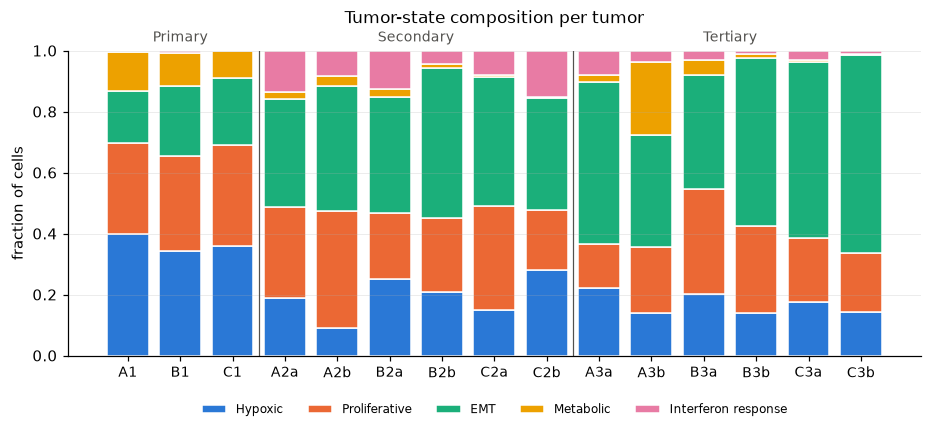

In [6]:
# Tumor-state composition of each tumor (the paper's 5 states).
comp = (meta.groupby(["tumor", "state"], observed=False).size().unstack(fill_value=0)
            .reindex(index=TUMORS, columns=STATE_NAMES, fill_value=0))
comp = comp.div(comp.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(10, 3.6))
bottom = np.zeros(len(comp))
for s in STATE_NAMES:
    ax.bar(range(len(comp)), comp[s], bottom=bottom, color=STATE_COLOR[s],
           edgecolor="white", linewidth=1, label=s)
    bottom += comp[s].to_numpy()
ax.set_xticks(range(len(comp)))
ax.set_xticklabels(comp.index, fontsize=9)
# Vertical rules separate the three generations; the labels above name them.
for x in [2.5, 8.5]:
    ax.axvline(x, color="#52514e", lw=0.8)
for x, st in zip([1, 5.5, 11.5], STAGES):
    ax.text(x, 1.03, st, ha="center", fontsize=9, color="#52514e")
ax.set_ylabel("fraction of cells")
ax.set_ylim(0, 1)
ax.set_title("Tumor-state composition per tumor", pad=18)
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.12), fontsize=8)
ax.grid(axis="x", visible=False)
plt.show()

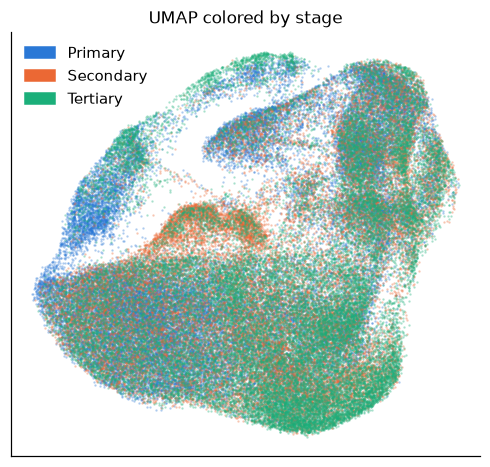

In [7]:
# Where each generation sits in expression space (the deposit's Harmony UMAP).
fig, ax = plt.subplots(figsize=(5.5, 5))
for st in STAGES:
    d = meta[meta.stage == st]
    ax.scatter(d.umap1, d.umap2, s=0.3, alpha=0.35, color=STAGE_COLOR[st], rasterized=True)
ax.legend(handles=[Patch(color=STAGE_COLOR[s], label=s) for s in STAGES], loc="best")
ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
ax.set_title("UMAP colored by stage")
plt.show()

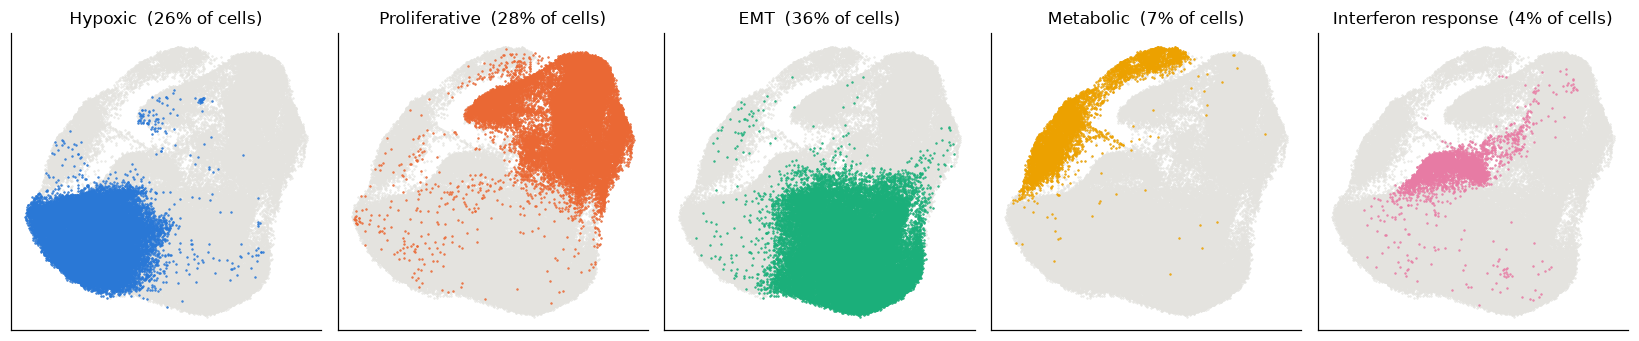

In [8]:
# The five tumor states on the same UMAP, one panel each.
fig, axs = plt.subplots(1, 5, figsize=(15, 3.2))
for ax, s in zip(axs, STATE_NAMES):
    ax.scatter(meta.umap1, meta.umap2, s=0.2, color="#e4e3df", rasterized=True)
    d = meta[meta.state == s]
    ax.scatter(d.umap1, d.umap2, s=0.3, color=STATE_COLOR[s], rasterized=True)
    ax.set_title(f"{s}  ({len(d) / len(meta):.0%} of cells)")
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
plt.tight_layout(); plt.show()

## 3. Clones

A clone is the set of cells sharing static barcodes. Clone numbers are shared
across families: all three founder tumors were seeded from one barcoded pool,
so clone 12 in family A and clone 12 in family C descend from the same
founder cell.

In [9]:
called = meta[meta.called]
# Per-clone summaries over clone-called cells only. `stages` / `families` count how many
# of the three each clone appears in.
# GLOSSARY.md: clone, bottleneck
per_clone = called.groupby("clone").agg(
    stages=("stage", "nunique"), families=("family", "nunique"), cells=("cell", "size"))

pd.DataFrame({
    "clones": [len(per_clone)],
    "in all 3 generations": [(per_clone.stages == 3).sum()],
    "in all 3 families": [(per_clone.families == 3).sum()],
    "median cells per clone": [int(per_clone.cells.median())],
    "largest clone (cells)": [per_clone.cells.max()],
})

,clones,in all 3 generations,in all 3 families,median cells per clone,largest clone (cells)
0,173,109,132,114,4542


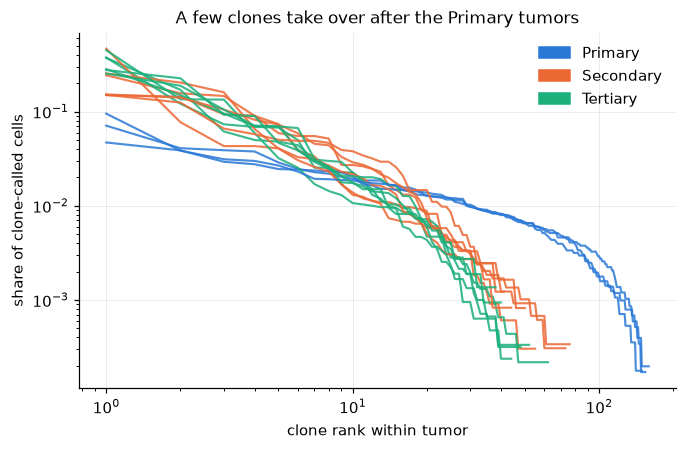

In [10]:
# Clone size distribution per tumor: the bottleneck.
# Each line is one tumor, clones ranked largest to smallest.
fig, ax = plt.subplots(figsize=(7, 4.2))
for t, d in called.groupby("tumor"):
    st = d.stage.iloc[0]
    frac = d.clone.value_counts(normalize=True).to_numpy()
    ax.plot(np.arange(1, len(frac) + 1), frac, color=STAGE_COLOR[st], lw=1.4, alpha=0.85)
# Log-log: a flat line is many clones of similar size; a steep drop is a few clones taking over.
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("clone rank within tumor")
ax.set_ylabel("share of clone-called cells")
ax.set_title("A few clones take over after the Primary tumors")
ax.legend(handles=[Patch(color=STAGE_COLOR[s], label=s) for s in STAGES])
plt.show()

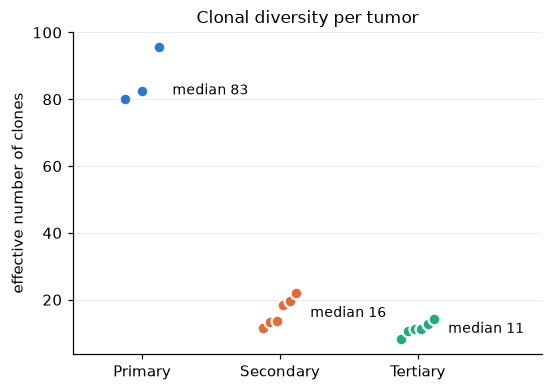

In [11]:
# Effective number of clones per tumor (exp of Shannon entropy).
# exp(entropy) = the number of equally sized clones that would give the same diversity.
# GLOSSARY.md: effective number of clones
def effective_clones(d):
    p = d.clone.value_counts(normalize=True)
    return np.exp(-(p * np.log(p)).sum())

eff = (called.groupby("tumor").apply(effective_clones).rename("effective_clones")
             .reset_index().merge(design[["tumor", "stage"]], on="tumor"))

fig, ax = plt.subplots(figsize=(5.5, 3.8))
for i, st in enumerate(STAGES):
    d = eff[eff.stage == st].sort_values("effective_clones")
    xs = np.full(len(d), i) + np.linspace(-0.12, 0.12, len(d))
    ax.scatter(xs, d.effective_clones, s=60, color=STAGE_COLOR[st],
               edgecolor="white", linewidth=1.5, zorder=3)
    ax.text(i + 0.22, d.effective_clones.median(), f"median {d.effective_clones.median():.0f}",
            va="center", fontsize=9)
ax.set_xticks(range(3)); ax.set_xticklabels(STAGES); ax.set_xlim(-0.5, 2.9)
ax.set_ylabel("effective number of clones")
ax.set_title("Clonal diversity per tumor")
ax.grid(axis="x", visible=False)
plt.show()

## 4. Clone trees

Each clone has an IQ-TREE phylogeny built from the evolving Cas9 edits, with
cells from all three generations and all three families in one tree
(`LineageTracing/single_cell/sc_trees_BLEELE/`). Leaves are cells; branch
lengths are edit distance, not time.

Two strips sit beside each tree: the **stage** of each cell and the
**family** it came from.

In [12]:
# One Newick tree per clone. `tree_layout` gives leaf order and x/y positions for drawing;
# `depth` is the longest root-to-leaf edit distance, so it is not comparable to time.
# GLOSSARY.md: clone tree, evolving barcode / Cas9 edits, Newick
trees = {clone_name(c): f for c, f in et.tree_files(P, "BLEELE").items()}
cell_info = meta.set_index("cell")[["stage", "family"]]

rows = []
for clone, f in trees.items():
    lay = et.tree_layout(et.read_newick(f))
    info = cell_info.reindex(lay["leaf_names"])
    rows.append(dict(clone=clone, cells=len(lay["leaves"]),
                     depth=round(float(lay["x"].max()), 3),
                     **{st: round((info.stage == st).mean(), 2) for st in STAGES},
                     families=info.family.nunique()))
tree_summary = pd.DataFrame(rows).sort_values("cells", ascending=False).reset_index(drop=True)
print(f"{len(tree_summary)} trees, {tree_summary.cells.sum():,} cells in total "
      "(stage columns are the fraction of the tree's cells)")
tree_summary.head(10)

173 trees, 46,328 cells in total (stage columns are the fraction of the tree's cells)


,clone,cells,depth,Primary,Secondary,Tertiary,families
0,clone 1,4560,0.333,0.04,0.62,0.34,3
1,clone 2,3448,0.100,0.04,0.37,0.57,3
2,clone 3,2406,0.120,0.04,0.37,0.58,2
3,clone 4,1803,0.184,0.07,0.05,0.88,3
4,clone 5,1505,0.179,0.03,0.23,0.74,3
5,clone 6,1351,0.081,0.07,0.54,0.39,3
6,clone 7,1257,0.056,0.93,0.06,0.00,3
7,clone 8,1012,0.150,0.22,0.46,0.32,3
8,clone 9,993,0.142,0.13,0.54,0.33,3
9,clone 10,960,0.143,0.07,0.18,0.75,2


In [13]:
def plot_clone_tree(ax, clone, lw=0.5):
    # Branches, then a stage strip and a family strip to the right of the leaves.
    lay = et.tree_layout(et.read_newick(trees[clone]))
    et.draw_tree(ax, lay, lw=lw)
    info = cell_info.reindex(lay["leaf_names"])
    y = lay["y"][lay["leaves"]]
    xmax = lay["x"].max()
    w = 0.06 * xmax
    for k, (col, cmap) in enumerate([("stage", STAGE_COLOR), ("family", FAMILY_COLOR)]):
        # Leaves with no metadata row are drawn white.
        colors = info[col].astype(object).map(cmap).fillna("#ffffff").to_numpy()
        ax.barh(y, w, left=xmax * 1.03 + k * w * 1.15, height=1.0, color=colors, linewidth=0)
    ax.set_ylim(-1, len(y))
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_title(f"{clone}  ({len(y):,} cells)")

tree_legend = ([Patch(color=STAGE_COLOR[s], label=s) for s in STAGES]
               + [Patch(color=c, label=f"family {f}") for f, c in FAMILY_COLOR.items()])

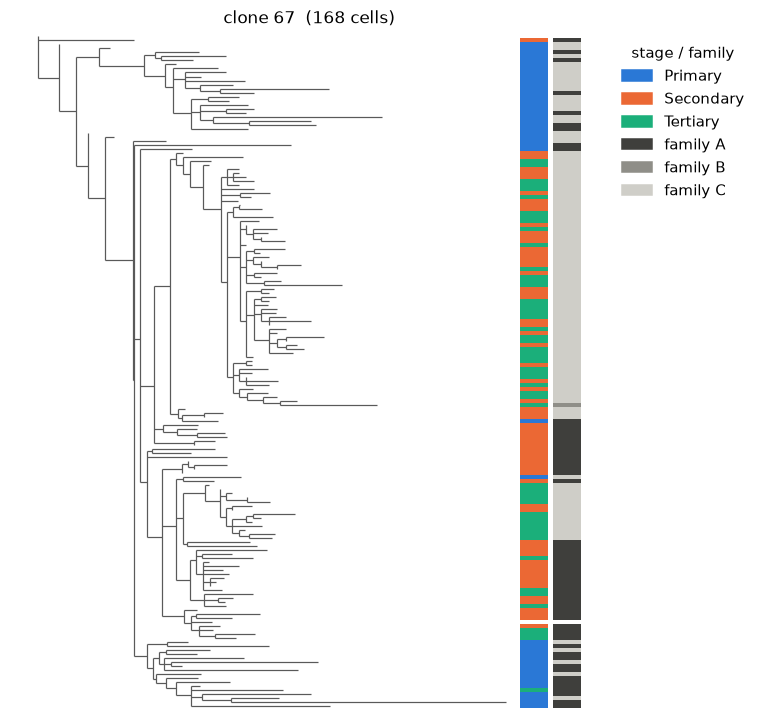

In [14]:
# One tree in detail: a 100-400 cell clone with all three generations well represented.
mid = tree_summary[tree_summary.cells.between(100, 400)]
example = mid.loc[mid[STAGES].min(axis=1).idxmax(), "clone"]

fig, ax = plt.subplots(figsize=(7, 8))
plot_clone_tree(ax, example, lw=0.8)
ax.legend(handles=tree_legend, loc="upper left", bbox_to_anchor=(1.0, 1.0), title="stage / family")
plt.show()

lost after Primary: 41 clones | reached Tertiary: 109 clones


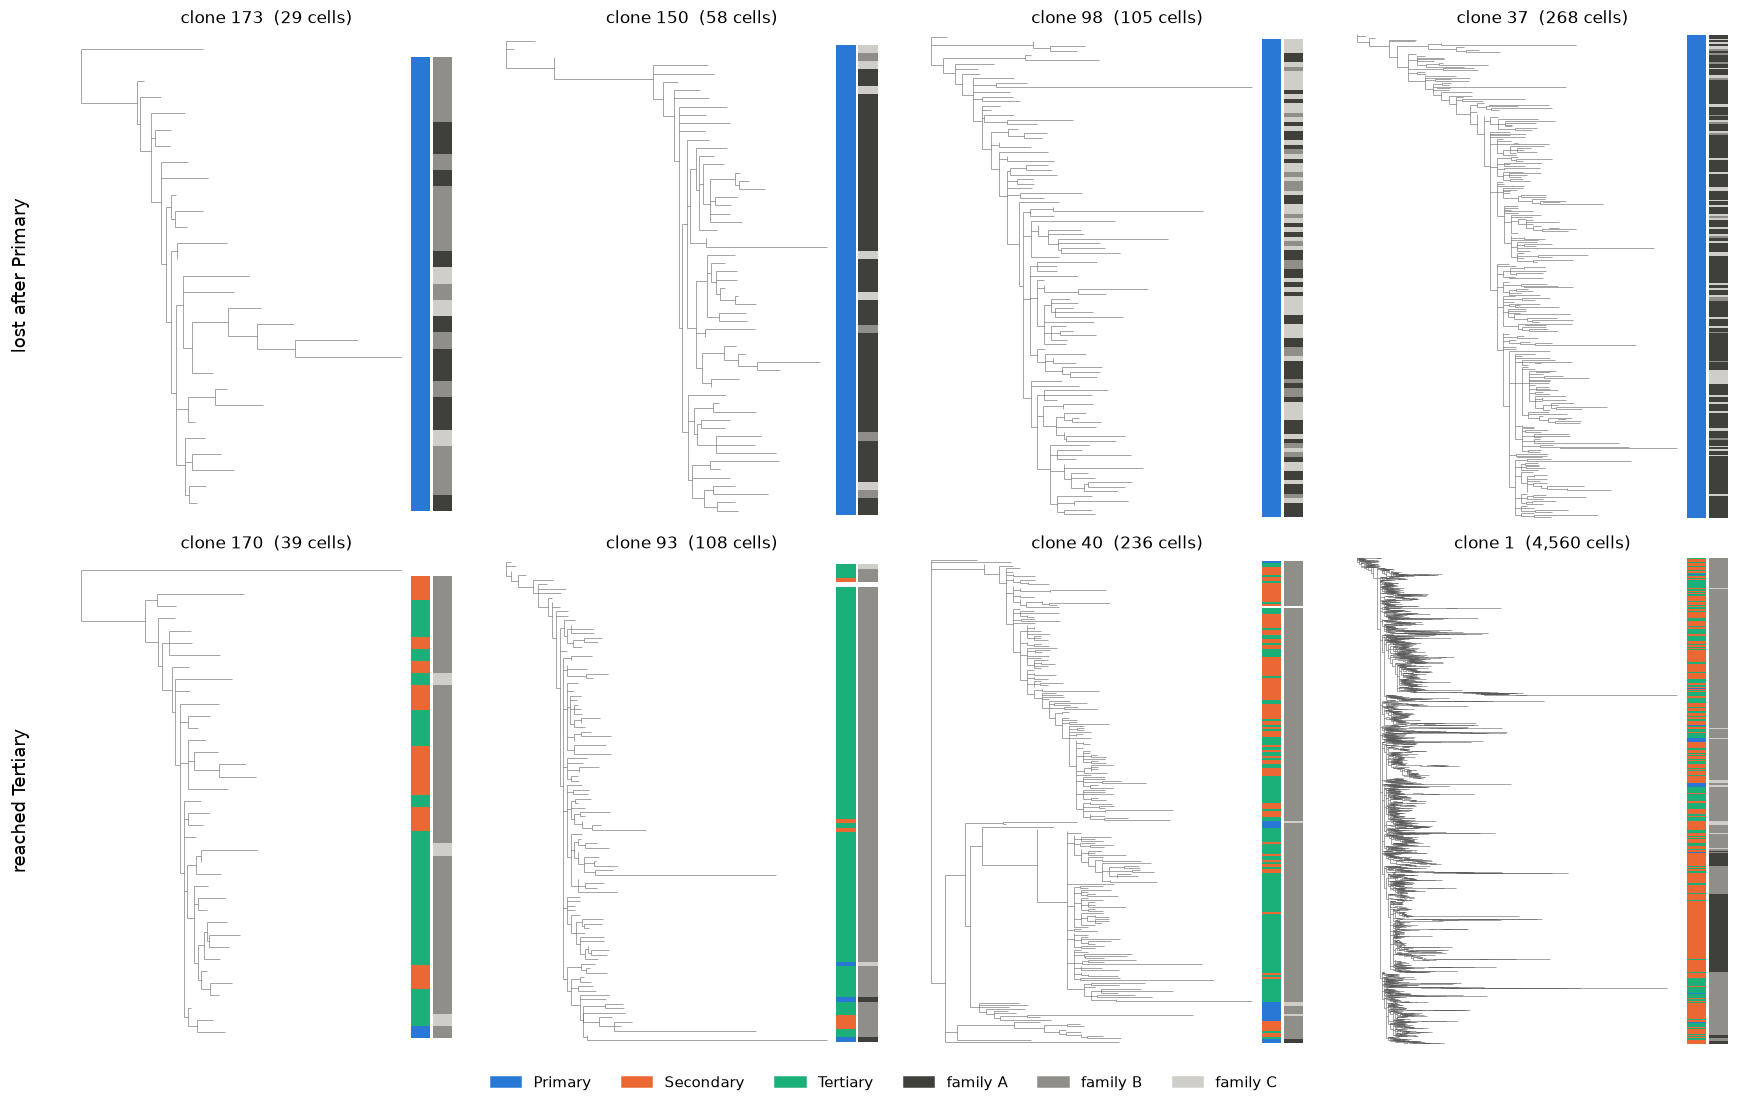

In [15]:
# Two fates side by side, four clones each, spread across the size range.
# Top row: clones whose tree has only Primary cells (lost after the Primary tumor).
# Bottom row: clones with cells in a Tertiary tumor.
def spread(d, k=4):
    d = d.sort_values("cells")
    return d.clone.to_numpy()[np.linspace(0, len(d) - 1, k).round().astype(int)]

lost = tree_summary[(tree_summary["Secondary"] + tree_summary["Tertiary"]) == 0]
kept = tree_summary[tree_summary["Tertiary"] > 0]
print(f"lost after Primary: {len(lost)} clones | reached Tertiary: {len(kept)} clones")

fig, axs = plt.subplots(2, 4, figsize=(16, 10))
for ax, c in zip(axs[0], spread(lost)):
    plot_clone_tree(ax, c, lw=0.35)
for ax, c in zip(axs[1], spread(kept)):
    plot_clone_tree(ax, c, lw=0.35)
axs[0, 0].text(-0.08, 0.5, "lost after Primary", transform=axs[0, 0].transAxes,
               rotation=90, va="center", ha="right", fontsize=12)
axs[1, 0].text(-0.08, 0.5, "reached Tertiary", transform=axs[1, 0].transAxes,
               rotation=90, va="center", ha="right", fontsize=12)
fig.legend(handles=tree_legend, loc="lower center", ncol=6, bbox_to_anchor=(0.5, -0.01))
plt.tight_layout(rect=(0, 0.03, 1, 1)); plt.show()

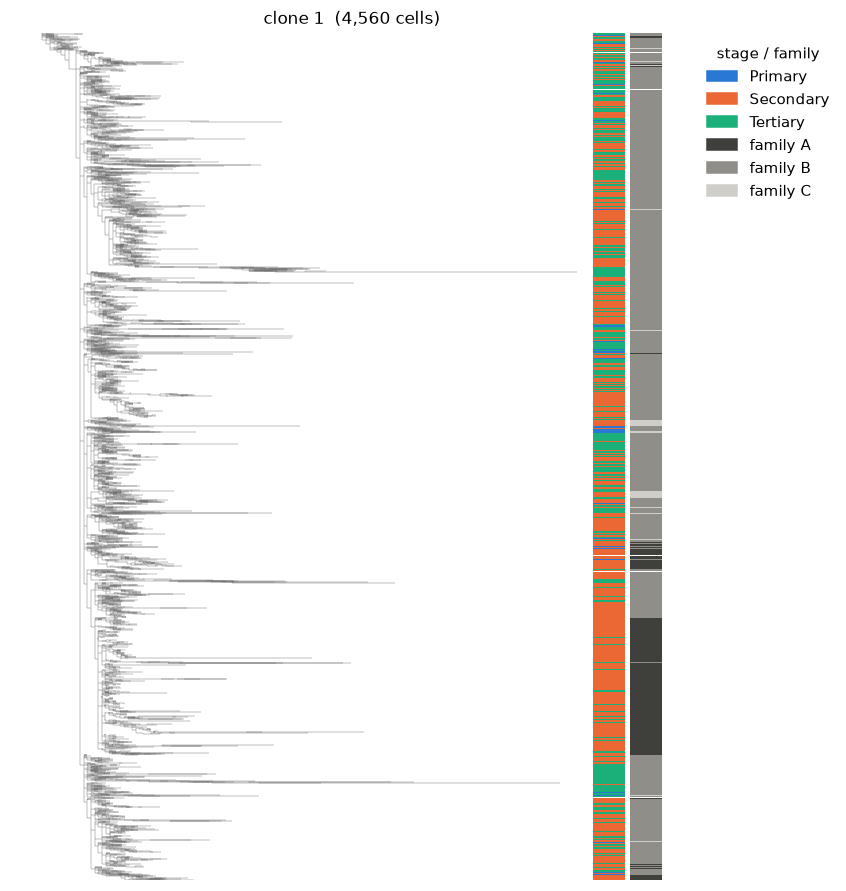

In [16]:
# The largest clone on its own: a few lineages inside it takes over in Secondary and Tertiary tumors.
fig, ax = plt.subplots(figsize=(8, 10))
plot_clone_tree(ax, tree_summary.clone.iloc[0], lw=0.25)
ax.legend(handles=tree_legend, loc="upper left", bbox_to_anchor=(1.0, 1.0), title="stage / family")
plt.show()

## 5. Clone survival to the next tumor

A clone in a parent tumor **survives** if at least one of its cells is seen
in the child tumor. Pairs follow the design: A1 → A2a and A2b, A2a → A3a,
A2b → A3b, and the same for B and C.

Caveat: only about half of the cells get a clone call, so a clone with a
handful of cells can be *missed* rather than extinct. The second plot shows
how survival depends on clone size.

In [17]:
# One row per (clone in a parent tumor, child tumor).
# `n` counts clone-called cells per (tumor, clone). A clone absent from the child gets
# n_child = 0, which cannot tell extinct from undetected (see the caveat above).
# GLOSSARY.md: survival (of a clone), lost / extinct vs missed
n = called.groupby(["tumor", "clone"]).size()
rows = []
for child in TUMORS:
    parent = parent_of(child)
    if not parent:
        continue
    for clone, n_parent in n.loc[parent].items():
        n_child = int(n.get((child, clone), 0))
        rows.append(dict(step=f"Generation {parent[1]} → {child[1]}", parent=parent, child=child,
                         clone=clone, n_cells_parent=int(n_parent), n_cells_child=n_child,
                         survived=n_child > 0))
surv = pd.DataFrame(rows)
surv.head()

,step,parent,child,clone,n_cells_parent,n_cells_child,survived
0,Generation 1 → 2,A1,A2a,clone 1,11,800,True
1,Generation 1 → 2,A1,A2a,clone 10,24,1,True
2,Generation 1 → 2,A1,A2a,clone 101,34,20,True
3,Generation 1 → 2,A1,A2a,clone 102,35,0,False
4,Generation 1 → 2,A1,A2a,clone 103,42,0,False


In [18]:
by_child = (surv.groupby(["step", "parent", "child"], sort=False)["survived"]
                .agg(clones="size", survived="sum").reset_index())
by_child["pct_survived"] = (100 * by_child.survived / by_child.clones).round(1)
by_child

,step,parent,child,clones,survived,pct_survived
0,Generation 1 → 2,A1,A2a,159,51,32.1
1,Generation 1 → 2,A1,A2b,159,48,30.2
2,Generation 1 → 2,B1,B2a,154,74,48.1
3,Generation 1 → 2,B1,B2b,154,73,47.4
4,Generation 1 → 2,C1,C2a,149,44,29.5
5,Generation 1 → 2,C1,C2b,149,40,26.8
6,Generation 2 → 3,A2a,A3a,55,36,65.5
7,Generation 2 → 3,A2b,A3b,50,40,80.0
8,Generation 2 → 3,B2a,B3a,76,55,72.4
9,Generation 2 → 3,B2b,B3b,73,51,69.9


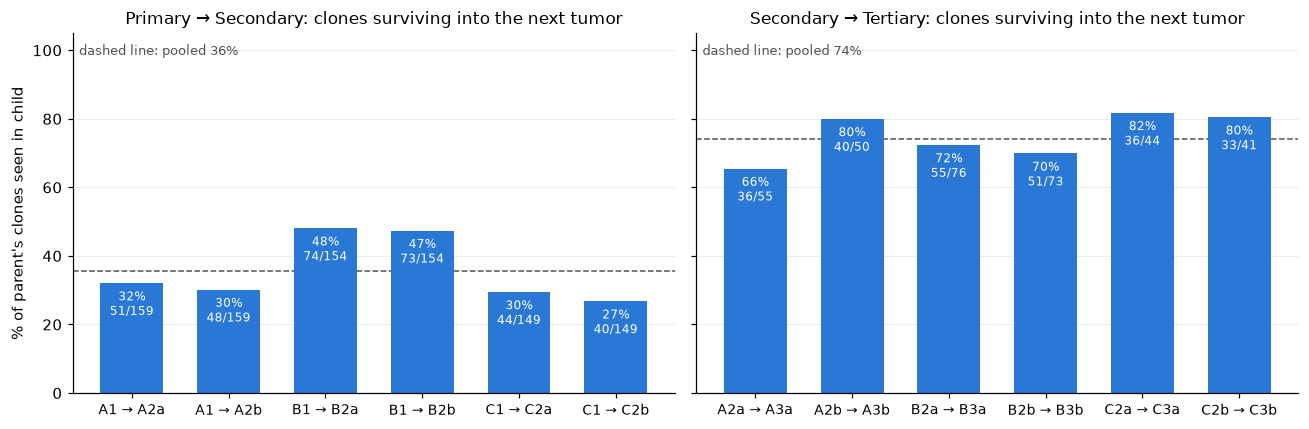

In [19]:
# Percentage of clones that survive into the next tumor.
STEP_TITLE = {"Generation 1 → 2": "Primary → Secondary",
              "Generation 2 → 3": "Secondary → Tertiary"}

fig, axs = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (step, d) in zip(axs, by_child.groupby("step", sort=False)):
    x = np.arange(len(d))
    ax.bar(x, d.pct_survived, color="#2a78d6", width=0.65, zorder=2)
    for xi, r in zip(x, d.itertuples()):
        ax.text(xi, r.pct_survived - 2, f"{r.pct_survived:.0f}%\n{r.survived}/{r.clones}",
                ha="center", va="top", fontsize=8, color="white")
    ax.set_xticks(x)
    ax.set_xticklabels([f"{p} → {c}" for p, c in zip(d.parent, d.child)], fontsize=9)
    pooled = 100 * d.survived.sum() / d.clones.sum()
    ax.axhline(pooled, color="#52514e", lw=1, ls="--", zorder=1)
    ax.text(0.01, 0.97, f"dashed line: pooled {pooled:.0f}%", transform=ax.transAxes,
            va="top", fontsize=8.5, color="#52514e")
    ax.set_title(f"{STEP_TITLE[step]}: clones surviving into the next tumor")
    ax.grid(axis="x", visible=False)
axs[0].set_ylabel("% of parent's clones seen in child")
axs[0].set_ylim(0, 105)
plt.tight_layout(); plt.show()

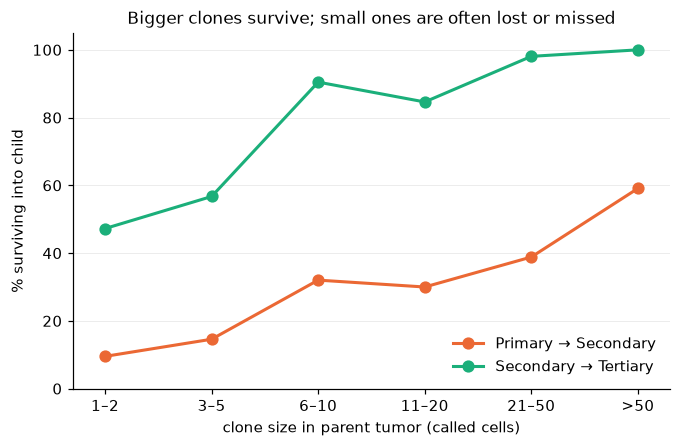

,Primary → Secondary,Secondary → Tertiary
size_bin,,
1–2,84,91
3–5,96,67
6–10,128,42
11–20,140,39
21–50,278,52
>50,198,48


In [20]:
# Survival by how big the clone was in the parent tumor.
# Bins on the clone's size in the parent tumor. The table below gives units per bin:
# the Secondary -> Tertiary curve rests on far fewer clones in the larger bins.
bins = [0, 2, 5, 10, 20, 50, np.inf]
labels = ["1–2", "3–5", "6–10", "11–20", "21–50", ">50"]
surv["size_bin"] = pd.cut(surv.n_cells_parent, bins, labels=labels)
by_size = (surv.groupby(["step", "size_bin"], observed=False)["survived"]
               .agg(["mean", "size"]).reset_index())

fig, ax = plt.subplots(figsize=(7, 4.2))
for step, color in [("Generation 1 → 2", STAGE_COLOR["Secondary"]),
                    ("Generation 2 → 3", STAGE_COLOR["Tertiary"])]:
    d = by_size[by_size.step == step]
    ax.plot(range(len(labels)), 100 * d["mean"], marker="o", ms=7, lw=2, color=color,
            label=STEP_TITLE[step])
ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels)
ax.set_xlabel("clone size in parent tumor (called cells)")
ax.set_ylabel("% surviving into child")
ax.set_ylim(0, 105); ax.set_xlim(-0.3, len(labels) - 0.7)
ax.set_title("Bigger clones survive; small ones are often lost or missed")
ax.legend(loc="lower right")
ax.grid(axis="x", visible=False)
plt.show()
(by_size.assign(step=by_size.step.map(STEP_TITLE))
        .pivot(index="size_bin", columns="step", values="size").rename_axis(None, axis=1))

## Summary

- **Design:** 3 families (A, B, C), 15 tumors (3 Primary → 6 Secondary →
  6 Tertiary), 91,411 cells.
- **Lineage labels:** about half of the cells in each generation carry a clone
  call (47% of Primary, 47% of Secondary, 57% of Tertiary cells). One tumor is the
  exception: C2b has clone calls for only 11% of its cells, which also lowers
  its survival bar.
- **Clones:** 173 clones, shared across families because all three founder
  tumors were seeded from one barcoded pool.
- **Bottleneck:** effective clonal diversity drops about fivefold from
  Primary to Secondary (median 83 → 16 effective clones) and a little
  further in Tertiary tumors (11).
- **Trees:** 173 per-clone phylogenies, one per clone, with cells from every
  generation and family in the same tree. Many trees contain only Primary
  cells: those clones were never seen again.
- **Survival:** 36% of a Primary tumor's clones are seen again in a
  Secondary tumor (27–48% per tumor); 74% of Secondary clones reach Tertiary
  (66–82%). Survival rises steeply with clone size, so part of the apparent
  loss is clones too small to be re-detected.